# Questão 1

In [ ]:
import networkx as nx
import numpy as np
import scipy
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(0)

In [3]:
N = 10000
k = 20
p = k/(N-1)

In [4]:
rede = nx.erdos_renyi_graph(N, p, seed=0)

In [5]:
graus = [d for _, d in rede.degree()]
graus = np.array(graus)
k_real =  np.mean(graus)
k_quadrado = np.mean(graus*graus)

print("k = ", k_real)
print("k² = ", k_quadrado)

k =  20.05
k² =  421.6942


In [6]:
def sis(rede, beta, mi, inicio=5, t_max = 500, seed=None, matriz_adj=None):
    rng = np.random.default_rng(seed)
    if matriz_adj is None:
        matriz_adj = nx.to_scipy_sparse_array(rede, weight=None, dtype=np.int32)
    N = matriz_adj.shape[0]

    infectados = np.zeros(N, dtype=bool)
    infectados[rng.choice(N, inicio, replace=False)] = True

    t = 1
    hist = np.zeros(t_max + 1)
    hist[0] = inicio

    while t <= t_max:

        vizinhos_inf = matriz_adj @ infectados
        p_inf = 1 - (1-beta) ** vizinhos_inf

        recuperados = infectados * (rng.random(N) < mi)
        novos_inf = ~infectados * (rng.random(N) < p_inf)

        infectados = infectados & ~recuperados | novos_inf       
        hist[t] = infectados.sum() 

        if not infectados.any():
            break

        t+=1

    return hist

    


In [7]:
def simular(rede, beta, mi, inicio = 5, t_max = 500, num_iter = 100, seed=0):
    matriz_adj = nx.to_scipy_sparse_array(rede, weight=None, dtype=np.int32)
    N = matriz_adj.shape[0]
    
    extintas = np.zeros(num_iter)
    ro = []
    total = []
    nao_ext = []
    tempos_ext = []

    for i in range(num_iter):
        hist = sis(rede, beta, mi, inicio, t_max, matriz_adj=matriz_adj, seed=seed+i)
        if hist[-1] ==0:
            extintas[i] = 1
            t_ext = np.flatnonzero(hist == 0)[0]
            tempos_ext.append(t_ext)
        else: 
            nao_ext.append(hist)
            ro.append(np.mean(hist[-100::])/N)
        total.append(hist)

    frac = extintas.mean()
    if nao_ext:
        media_cond = np.mean(nao_ext, axis=0)/N
        p1 = np.quantile(nao_ext, 0.1, axis=0)/N
        p9 = np.quantile(nao_ext, 0.9, axis=0)/N
    else: media_cond = p1 = p9 = np.full(t_max+1, np.nan)
    
    media_incond = np.mean(total, axis=0)/N
    return dict(frac_ext=frac, t_ext=np.mean(tempos_ext) if tempos_ext else np.nan,
                media_cond=media_cond, p10=p1, p90=p9,
                rho_est=ro, media_incond=media_incond, num_sobreviventes = len(nao_ext))

## Item 1.1

In [8]:
#calculando R₀ = e ρ*


mi_values = [0.1, 0.3, 0.5, 0.4]
beta = 0.02

for mi in mi_values:
    r0 = beta*k/mi
    print("#"*60)
    print("mi = ", mi)
    print("R0 = ", r0)
    print("ρ* = ", max(1 - 1/r0, 0))

############################################################
mi =  0.1
R0 =  4.0
ρ* =  0.75
############################################################
mi =  0.3
R0 =  1.3333333333333335
ρ* =  0.2500000000000001
############################################################
mi =  0.5
R0 =  0.8
ρ* =  0
############################################################
mi =  0.4
R0 =  1.0
ρ* =  0.0


In [9]:
# simulação

resultados = []

for mi in mi_values:
    resultados.append(simular(rede, beta, mi))


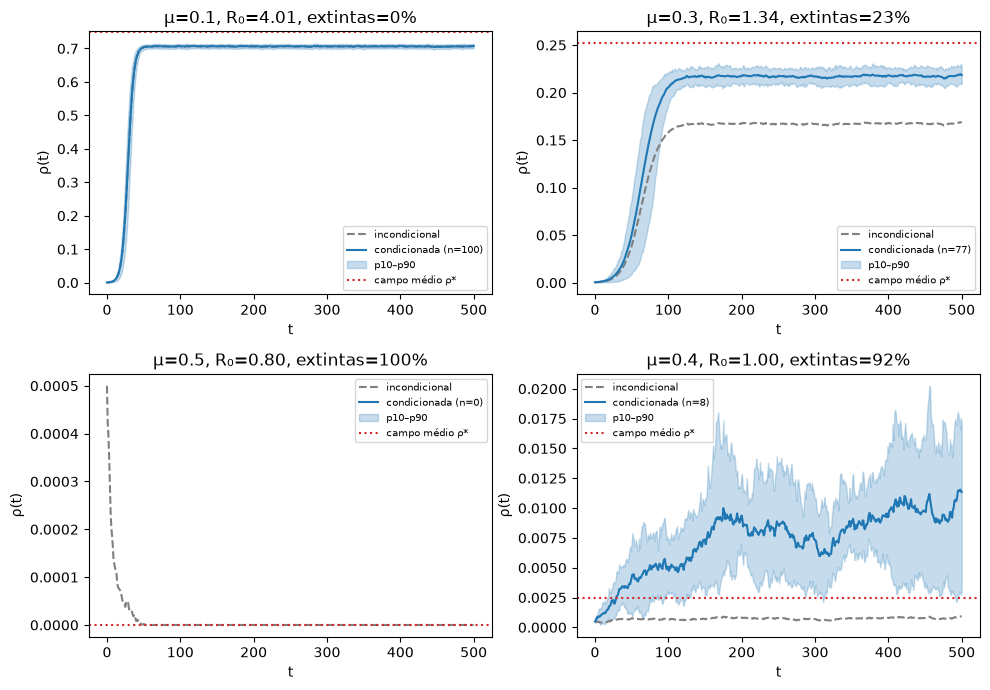

In [10]:
#plot dos resultados obtidos

t = np.arange(len(resultados[0]["media_incond"]))

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, r, mi in zip(axes.flat, resultados, mi_values):
    R0 = beta * k_real / mi
    ax.plot(t, r["media_incond"], "--", c="gray", label="incondicional")
    ax.plot(t, r["media_cond"], c="C0", label=f"condicionada (n={r['num_sobreviventes']})")
    ax.fill_between(t, r["p10"], r["p90"], color="C0", alpha=0.25, label="p10–p90")
    ax.axhline(max(0, 1 - 1/R0), c="C3", ls=":", label="campo médio ρ*")
    ax.set_title(f"μ={mi}, R₀={R0:.2f}, extintas={r['frac_ext']:.0%}")
    ax.set_xlabel("t"); ax.set_ylabel("ρ(t)"); ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

> Discussão das diferenças

## Item 1.2

### 1)
$$
\rho = \rho - \mu\rho + \beta ⟨k⟩ \rho (1-\rho) \iff \mu\rho = \beta ⟨k⟩  \rho (1-\rho) \iff
$$

$$
\begin{cases}
\rho = 0 \\
\frac{1}{1-\rho} = \frac{\beta ⟨k⟩}{\mu} = R_0 \iff 1-\rho = 
\frac{1}{R_0} \iff \rho = 1- \frac{1}{R_0}
\end{cases}
$$


Vemos, então, que se $\rho = 0$ ou $\rho = 1- \frac{1}{R_0}$, teremos um ponto fixo.


Se $R_0 \leq 1$, a última igualdade nunca será verdadeira porque teremos $1 - \frac{1}{R_0} < 0$, mas $0 \leq \rho \leq 1$. Logo, só teremos um ponto fixo nesse caso se $\rho = 0$ 

### 2)
$$
g'(\rho)= 1 - \mu + \beta ⟨k⟩(1 - 2\rho)
$$


$$
R_0 > 1 \implies β⟨k⟩/μ > 1 \implies β⟨k⟩ - μ > 0
$$

$$
g'(0) = 1 - \mu + \beta ⟨k⟩ > 1
$$

$$
g'(\rho*) = 1 - \mu + \beta ⟨k⟩(-1 + 2\mu/\beta⟨k⟩) = 1 - \beta⟨k⟩ +\mu
$$

$$
0 <\mu (R_0 - 1) <2 \implies 0< \beta⟨k⟩ - \mu < 2 \implies \\ -1 < 1 - \beta⟨k⟩ +\mu < 1 \implies |g'(\rho*)|<1
$$


### 3)

$$
\rho_{t+1} = \rho_t - \mu \rho_t + \beta⟨𝑘⟩ \rho_t (1 - \rho_t) 
$$
Vamos avaliar a expressão $- \mu \rho_t + \beta⟨𝑘⟩ \rho_t (1 - \rho_t)$:

$0 < \rho_t < 1 - 1/R_0 $

$$
- \mu \rho_t + \beta⟨𝑘⟩ \rho_t (1 - \rho_t) > - \mu \rho_t + \beta⟨𝑘⟩ \rho_t (1/R_0) \\= - \mu \rho_t + \beta⟨𝑘⟩ \rho_t (\mu/\beta⟨𝑘⟩) =  - \mu \rho_t + \rho_t \mu = 0 \\ 
\implies - \mu \rho_t + \beta⟨𝑘⟩ \rho_t (1 - \rho_t) > 0 \implies \rho_{t+1} > \rho_t
$$ 


In [11]:
# Iterando
def pt_next(pt, beta, mu, k):
    return pt - mu*pt + beta*k*pt*(1-pt)

mi_rho = {mi : max(1 - 1/(beta*k/mi), 0) for mi in mi_values}

pt = 5/N

for mi in mi_values:
    print("#"*60)
    print("mi = ", mi)
    pts = []
    for i in range(500):
        pt = pt_next(pt, beta, mi, k)
        pts.append(pt)
    print(pts)
    print("diff = ", pts[-1] - mi_rho[mi])
        

############################################################
mi =  0.1
[0.0006499, 0.000844701051996, 0.0010978259596479028, 0.001426691658807203, 0.00185388497681364, 0.00240867571405483, 0.0031289577407930882, 0.004063728912413547, 0.005276242029068176, 0.006847979145808906, 0.008883614962199006, 0.011517132004940065, 0.014919213874574398, 0.0193059448598926, 0.024948640515087096, 0.03218425880419281, 0.04142520583954055, 0.05316634851986339, 0.06798558882984818, 0.08653244936338615, 0.10949703825527121, 0.13755030917718203, 0.17124736690844128, 0.21089131271174394, 0.2563686482143541, 0.3069892891637583, 0.36138910644837796, 0.4175650038790685, 0.47309029205697845, 0.5254916098986491, 0.5726825200386942, 0.6133011685471548, 0.646836189774779, 0.6735282241462711, 0.6941305839015006, 0.7096428520689755, 0.7210985166926321, 0.7294348433898961, 0.7354352201063681, 0.7397198009491176, 0.742761587667372, 0.7449121535219215, 0.7464281529926312, 0.7474946038584243, 0.7482437118969665, 0.748

Como podemos observar, a diferença entre o último valor computado e $\rho*$ é muito próxima de 0.

# Questão 2

In [12]:
y = 2.5
N = 10000
k = 20
k_min = 8
k_max = 450


In [13]:
sequencia_graus = []
while len(sequencia_graus) < N:
    # Gera em lote para ser rápido
    amostra = nx.utils.powerlaw_sequence(N, y)
    for x in amostra:
        k = int(round(x * k_min))
        if k <= k_max:
            sequencia_graus.append(k)
            if len(sequencia_graus) == N:
                break

if sum(sequencia_graus) % 2 != 0:
    sequencia_graus[0] += 1

# 3. Cria e limpa o grafo
G = nx.Graph(nx.configuration_model(sequencia_graus, seed=42))
G.remove_edges_from(nx.selfloop_edges(G))


In [24]:
graus = [d for _, d in G.degree()]
graus = np.array(graus)
k_real =  np.mean(graus)
k_quadrado = np.mean(graus*graus)

adj = nx.adjacency_matrix(G, dtype=int)
lambda1 = scipy.sparse.linalg.eigsh(adj, k=1, which='LA', return_eigenvectors=False)

print("k = ", k_real)
print("k² = ", k_quadrado)
print("k max = ", max(graus))
print("maior autovalor", lambda1[0])


k =  20.6252
k² =  1177.0448
k max =  414
maior autovalor 57.2825934427089


In [26]:
mi_values = [0.1, 0.2, 0.3]
beta = 0.01

In [32]:
# simulação

resultados = []

for mi in mi_values:
    resultados.append(simular(G, beta, mi))


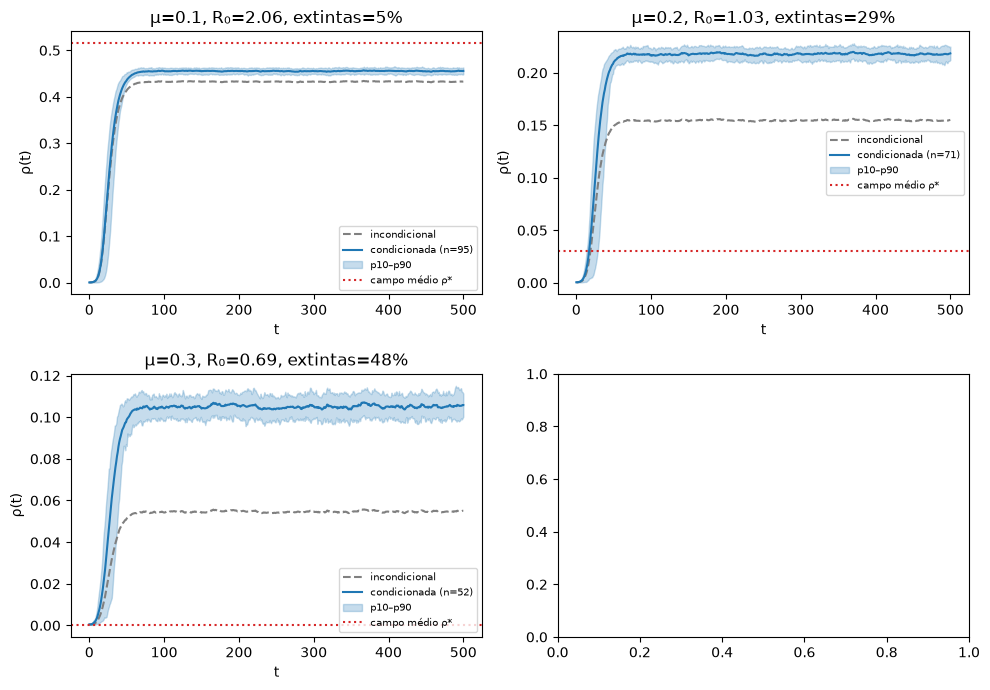

In [33]:
#plot dos resultados obtidos

t = np.arange(len(resultados[0]["media_incond"]))

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, r, mi in zip(axes.flat, resultados, mi_values):
    R0 = beta * k_real / mi
    ax.plot(t, r["media_incond"], "--", c="gray", label="incondicional")
    ax.plot(t, r["media_cond"], c="C0", label=f"condicionada (n={r['num_sobreviventes']})")
    ax.fill_between(t, r["p10"], r["p90"], color="C0", alpha=0.25, label="p10–p90")
    ax.axhline(max(0, 1 - 1/R0), c="C3", ls=":", label="campo médio ρ*")
    ax.set_title(f"μ={mi}, R₀={R0:.2f}, extintas={r['frac_ext']:.0%}")
    ax.set_xlabel("t"); ax.set_ylabel("ρ(t)"); ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

## Item 2.1
> discussão 

## Item 2.2

In [34]:
for mi in mi_values:
    print("#"*60)
    print("𝜇 =", mi)
    print("𝑅0hom = ", beta*k_real/mi)
    print("𝑅0het = ", beta*k_quadrado/(mi*k_real))
    print("𝑅0quenched = ", beta*lambda1[0]/mi)



############################################################
𝜇 = 0.1
𝑅0hom =  2.0625199999999997
𝑅0het =  5.706828539844461
𝑅0quenched =  5.7282593442708905
############################################################
𝜇 = 0.2
𝑅0hom =  1.0312599999999998
𝑅0het =  2.8534142699222307
𝑅0quenched =  2.8641296721354452
############################################################
𝜇 = 0.3
𝑅0hom =  0.6875066666666667
𝑅0het =  1.9022761799481542
𝑅0quenched =  1.9094197814236302


> discussão

## Item 2.3

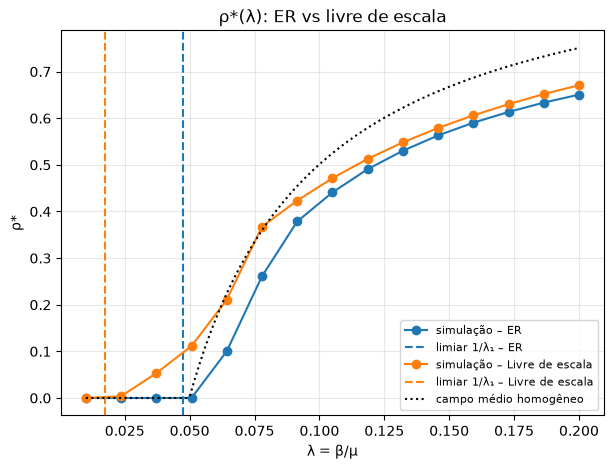

In [35]:
def lambda1(rede):
    A = nx.to_scipy_sparse_array(rede, dtype=float)
    return scipy.sparse.linalg.eigsh(A, k=1, which="LA", return_eigenvectors=False)[0]

def rho_estacionario(rede, beta, mi, num_iter=10, t_max=500):
    """ρ* médio (últimos 100 passos), média sobre num_iter simulações.
    Simulações extintas contam como ρ = 0."""
    A = nx.to_scipy_sparse_array(rede, weight=None, dtype=np.int32)
    N = A.shape[0]
    rhos = [sis(rede, beta, mi, t_max=t_max, matriz_adj=A, seed=i)[-100:].mean() / N
            for i in range(num_iter)]
    return np.mean(rhos)

beta = 0.01
lambdas = np.linspace(0.01, 0.2, 15)
redes = {"ER": rede, "Livre de escala": G}

plt.figure(figsize=(7, 5))
for i, (nome, r) in enumerate(redes.items()):
    rho = [rho_estacionario(r, beta, beta / lam) for lam in lambdas]
    plt.plot(lambdas, rho, "o-", color=f"C{i}", label=f"simulação – {nome}")
    plt.axvline(1 / lambda1(r), color=f"C{i}", ls="--",
                label=f"limiar 1/λ₁ – {nome}")

k_er = np.mean([d for _, d in rede.degree()])
lam_fino = np.linspace(0.01, 0.2, 200)
plt.plot(lam_fino, np.maximum(1 - 1 / (lam_fino * k_er), 0), "k:",
         label="campo médio homogêneo")

plt.xlabel("λ = β/μ"); plt.ylabel("ρ*")
plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title("ρ*(λ): ER vs livre de escala")
plt.show()

> Discussão

Fixei β = 0,01 e variei μ = β/λ para varrer λ nas duas redes. As linhas tracejadas marcam o limiar teórico de cada rede, λc = 1/λ₁ (aproximação *quenched*), e a linha pontilhada preta é a curva de campo médio homogêneo ρ* = 1 − 1/(λ⟨k⟩).

**Limiar.** Na ER, λ₁ ≈ ⟨k⟩ + 1, então λc ≈ 1/⟨k⟩ ≈ 0,05. Na rede livre de escala (γ = 2,5), λ₁ é bem maior, pois a rede tem hubs e ⟨k²⟩ ≫ ⟨k⟩². Assim λc é bem menor, e a epidemia persiste mesmo com λ pequeno.

**Forma da curva.** Na ER, ρ* é nulo abaixo do limiar e cresce de forma aproximadamente linear acima dele, de acordo com o campo médio homogêneo. Na rede livre de escala, ρ* começa a crescer em λ muito menor e sobe de forma mais suave e convexa perto do limiar (transição "arredondada"), pois os hubs sustentam a infecção e os nós de grau baixo são infectados por eles.

**Observação.** Perto do limiar, as simulações com 5 infectados iniciais podem se extinguir cedo por efeito estocástico, e o tamanho finito (N = 10⁴) também suaviza a transição. Isso faz o ρ* simulado ficar um pouco abaixo da teoria.